# Mini-Projet 04: Bike Sharing demand forecasting
**Models trained:** Ridge Regression and Random Forest Regressor
**Protocol:** chronological split 80/20, tuning with `TimeSeriesSplit` on the train set only, a single evaluation on the test set.

Notebook outline:
1. Imports and loading
2. Exploratory analysis
3. Feature preparation and chronological split
4. How `TimeSeriesSplit` cuts the train set
5. Data pipeline + model pipelines
6. Tuning (train set only)
7. Training graphs (CV curves)
8. Final evaluation on test (R2, MAE, RMSE) and graphs
9. Saving the trained models and pipelines
10. Reloading a saved model (check)

## 1. Imports and loading

In [1]:
import os, io, zipfile, urllib.request, warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")
RS = 42
np.random.seed(RS)
plt.rcParams["figure.dpi"] = 110
os.makedirs("saved_models", exist_ok=True)

In [3]:
df = pd.read_csv("../hour.csv", parse_dates=["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)   # chronological order
print(df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.head()

(17379, 17)
Missing values: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 2. Exploratory analysis

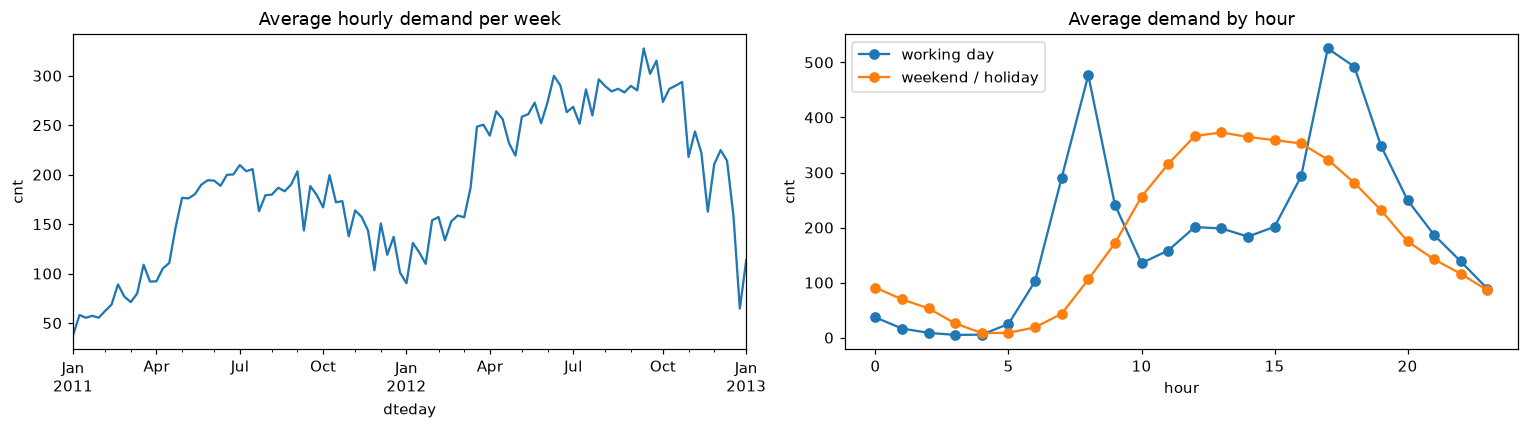

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

# Demand over time (weekly mean)
df.set_index("dteday")["cnt"].resample("W").mean().plot(ax=ax[0])
ax[0].set_title("Average hourly demand per week")
ax[0].set_ylabel("cnt")

# Average profile by hour
for wd, lab in [(1, "working day"), (0, "weekend / holiday")]:
    prof = df[df["workingday"] == wd].groupby("hr")["cnt"].mean()
    ax[1].plot(prof.index, prof.values, marker="o", label=lab)
ax[1].set_title("Average demand by hour")
ax[1].set_xlabel("hour"); ax[1].set_ylabel("cnt"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Feature preparation and chronological split
- Target: `cnt`
- Removed from the inputs: `cnt`, `casual`, `registered` (their sum is `cnt`, so they leak the target), `instant` (identifier), `dteday` (date, already used for sorting).
- Periodic variables (`hr`, `mnth`, `weekday`) are encoded with sin/cos so that, for example, hour 23 is close to hour 0.
- The split is chronological: first 80% for train, last 20% for test, **no shuffle**.

In [5]:
def make_features(data):
    """Raw dataframe -> feature matrix X (same function is reused for new data)."""
    X = data.drop(columns=["cnt", "casual", "registered", "instant", "dteday"], errors="ignore").copy()
    # cyclical encoding for periodic variables
    for col, period in [("hr", 24), ("mnth", 12), ("weekday", 7)]:
        X[col + "_sin"] = np.sin(2 * np.pi * X[col] / period)
        X[col + "_cos"] = np.cos(2 * np.pi * X[col] / period)
    # the sin/cos columns replace the raw periodic columns
    return X.drop(columns=["hr", "mnth", "weekday"])

y = df["cnt"]
X = make_features(df)

cat_cols = ["season", "weathersit"]
num_cols = ["temp", "atemp", "hum", "windspeed"]
bin_cols = ["yr", "holiday", "workingday"]
cyc_cols = [c for c in X.columns if c.endswith(("_sin", "_cos"))]

n = int(len(X) * 0.8)
X_train, X_test = X.iloc[:n], X.iloc[n:]
y_train, y_test = y.iloc[:n], y.iloc[n:]
hr_test = df["hr"].iloc[n:]          # raw hour kept for the error analysis

print("Train:", X_train.shape, df["dteday"].iloc[0].date(), "->", df["dteday"].iloc[n-1].date())
print("Test :", X_test.shape,  df["dteday"].iloc[n].date(),  "->", df["dteday"].iloc[-1].date())
print("Columns:", list(X.columns))

Train: (13903, 15) 2011-01-01 -> 2012-08-07
Test : (3476, 15) 2012-08-07 -> 2012-12-31
Columns: ['season', 'yr', 'holiday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'weekday_sin', 'weekday_cos']


## 4. How `TimeSeriesSplit` cuts the train set
Blue = training part, orange = validation part. The validation block is always **after** the training block.

Fold 1: train rows 0-2317  ->  val rows 2318-4634
Fold 2: train rows 0-4634  ->  val rows 4635-6951
Fold 3: train rows 0-6951  ->  val rows 6952-9268
Fold 4: train rows 0-9268  ->  val rows 9269-11585
Fold 5: train rows 0-11585  ->  val rows 11586-13902


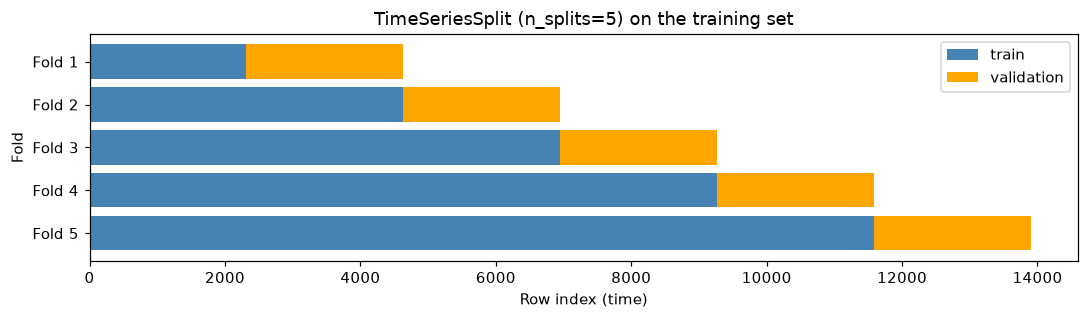

In [6]:
tscv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(10, 3))
for i, (tr, va) in enumerate(tscv.split(X_train)):
    ax.barh(i, len(tr), left=0, color="steelblue", label="train" if i == 0 else None)
    ax.barh(i, len(va), left=tr[-1] + 1, color="orange", label="validation" if i == 0 else None)
    print(f"Fold {i+1}: train rows {tr[0]}-{tr[-1]}  ->  val rows {va[0]}-{va[-1]}")
ax.set_xlabel("Row index (time)"); ax.set_ylabel("Fold"); ax.set_yticks(range(5))
ax.set_yticklabels([f"Fold {i+1}" for i in range(5)]); ax.invert_yaxis(); ax.legend()
ax.set_title("TimeSeriesSplit (n_splits=5) on the training set")
plt.tight_layout(); plt.show()

## 5. Data pipeline and model pipelines
The **data pipeline** (`ColumnTransformer`) does:
- numeric weather variables -> `StandardScaler`
- categorical variables (`season`, `weathersit`) -> `OneHotEncoder`
- binary and cyclic variables -> passed through unchanged

It is placed **inside** each model pipeline, so during cross-validation it is re-fitted on the training fold only (no leakage from the validation fold).

In [7]:
def build_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("pass", "passthrough", bin_cols + cyc_cols),
    ])

pipe_ridge = Pipeline([("pre", build_preprocessor()),
                       ("m", Ridge(random_state=RS))])

pipe_rf = Pipeline([("pre", build_preprocessor()),
                    ("m", RandomForestRegressor(random_state=RS, n_jobs=-1))])

param_grids = {
    "Ridge":         {"m__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]},
    "Random Forest": {"m__n_estimators": [100, 300], "m__max_depth": [8, 12, 16, None]},
}
pipelines = {"Ridge": pipe_ridge, "Random Forest": pipe_rf}
pipe_ridge

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('m', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## 6. Tuning with `TimeSeriesSplit` (train set only)
`GridSearchCV` tries every hyperparameter combination, trains on the growing window and validates on the next block, then averages the 5 RMSE values. `return_train_score=True` also keeps the training RMSE so we can plot train vs validation.
The test set is not used here.

In [8]:
searches = {}
for name, pipe in pipelines.items():
    gs = GridSearchCV(pipe, param_grids[name], cv=tscv,
                      scoring="neg_root_mean_squared_error",
                      return_train_score=True, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)          # refit=True -> best model re-trained on the whole train set
    searches[name] = gs
    print(f"{name:14s} best params: {gs.best_params_}   CV RMSE = {-gs.best_score_:.2f}")

best_models = {name: gs.best_estimator_ for name, gs in searches.items()}

Ridge          best params: {'m__alpha': 0.001}   CV RMSE = 130.44
Random Forest  best params: {'m__max_depth': 12, 'm__n_estimators': 300}   CV RMSE = 81.68


In [9]:
# Table of best parameters and CV score
pd.DataFrame({
    "Model": list(searches),
    "Best params": [str(gs.best_params_) for gs in searches.values()],
    "CV RMSE": [-gs.best_score_ for gs in searches.values()],
}).round(2)

,Model,Best params,CV RMSE
0,Ridge,{'m__alpha': 0.001},130.44
1,Random Forest,"{'m__max_depth': 12, 'm__n_estimators': 300}",81.68


## 7. Training graphs (cross-validation curves)

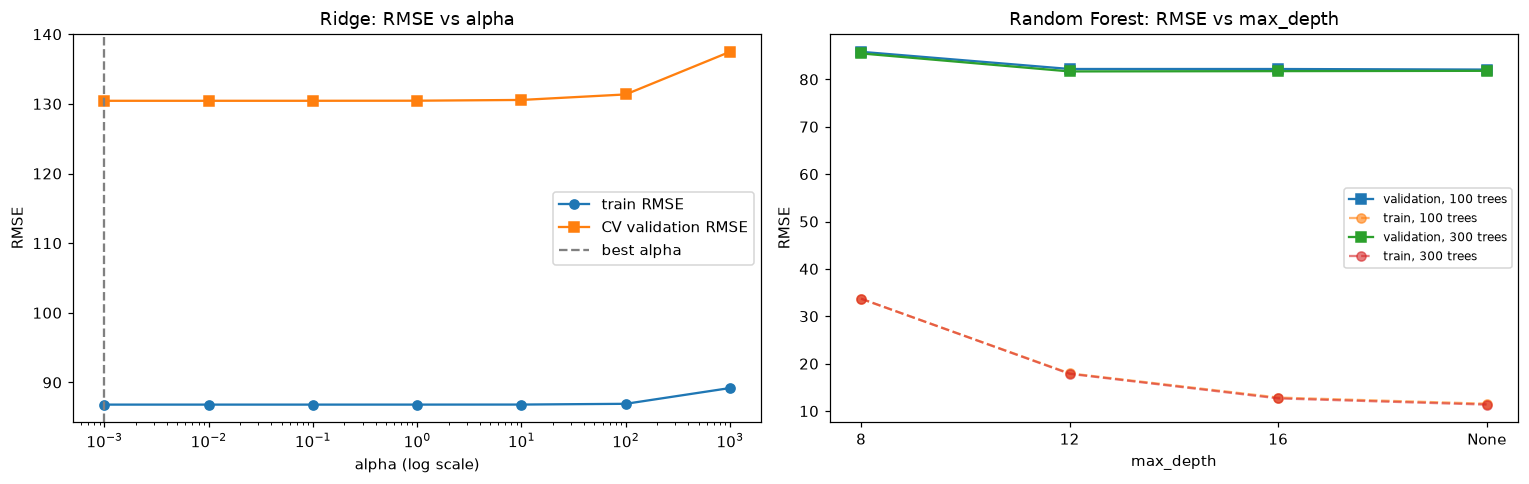

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# --- Ridge: RMSE vs alpha (train vs validation)
r = pd.DataFrame(searches["Ridge"].cv_results_)
alphas = r["param_m__alpha"].astype(float)
ax[0].semilogx(alphas, -r["mean_train_score"], "o-", label="train RMSE")
ax[0].semilogx(alphas, -r["mean_test_score"], "s-", label="CV validation RMSE")
ax[0].axvline(searches["Ridge"].best_params_["m__alpha"], color="gray", ls="--", label="best alpha")
ax[0].set_title("Ridge: RMSE vs alpha"); ax[0].set_xlabel("alpha (log scale)"); ax[0].set_ylabel("RMSE")
ax[0].legend()

# --- Random Forest: RMSE vs max_depth for each n_estimators
r = pd.DataFrame(searches["Random Forest"].cv_results_)
r["depth"] = r["param_m__max_depth"].apply(lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
order = ["8", "12", "16", "None"]
for ne, g in r.groupby("param_m__n_estimators"):
    g = g.set_index("depth").loc[order]
    ax[1].plot(order, -g["mean_test_score"], "s-", label=f"validation, {ne} trees")
    ax[1].plot(order, -g["mean_train_score"], "o--", alpha=0.6, label=f"train, {ne} trees")
ax[1].set_title("Random Forest: RMSE vs max_depth"); ax[1].set_xlabel("max_depth"); ax[1].set_ylabel("RMSE")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

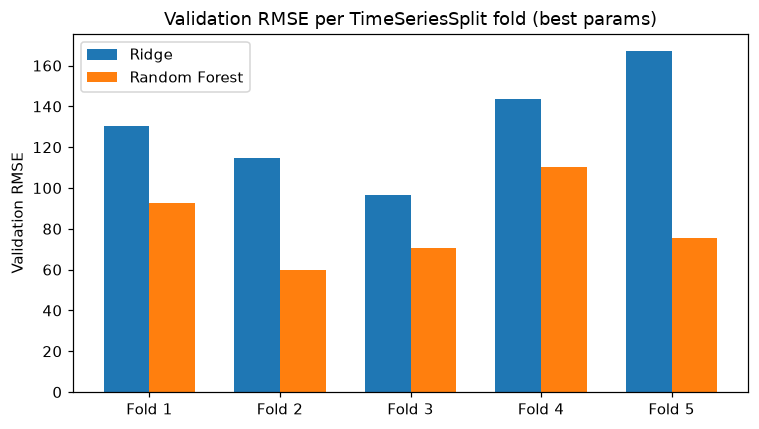

In [11]:
# RMSE of the best configuration in each of the 5 folds
fig, ax = plt.subplots(figsize=(7, 4))
width = 0.35
for k, (name, gs) in enumerate(searches.items()):
    r = pd.DataFrame(gs.cv_results_).iloc[gs.best_index_]
    fold_rmse = [-r[f"split{i}_test_score"] for i in range(5)]
    ax.bar(np.arange(5) + k * width, fold_rmse, width, label=name)
ax.set_xticks(np.arange(5) + width / 2); ax.set_xticklabels([f"Fold {i+1}" for i in range(5)])
ax.set_ylabel("Validation RMSE"); ax.set_title("Validation RMSE per TimeSeriesSplit fold (best params)")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Final evaluation on the chronological test set
Each model predicts the test set **once**. No retuning after this step. Negative predictions are clipped to 0 (a count cannot be negative).

In [12]:
def evaluate(y_true, y_pred):
    y_pred = np.clip(y_pred, 0, None)
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

rows, preds = [], {}
for name, est in best_models.items():
    p_tr = est.predict(X_train)
    p_te = np.clip(est.predict(X_test), 0, None)      # single test evaluation
    preds[name] = p_te
    m_tr, m_te = evaluate(y_train, p_tr), evaluate(y_test, p_te)
    rows.append({"Model": name,
                 "Train MAE": m_tr["MAE"], "Train RMSE": m_tr["RMSE"], "Train R2": m_tr["R2"],
                 "Test MAE": m_te["MAE"],  "Test RMSE": m_te["RMSE"],  "Test R2": m_te["R2"]})
results = pd.DataFrame(rows).set_index("Model")
results.round(3)

,Train MAE,Train RMSE,Train R2,Test MAE,Test RMSE,Test R2
Model,,,,,,
Ridge,82.713,115.951,0.518,120.709,164.405,0.444
Random Forest,15.733,24.635,0.978,55.359,82.034,0.862


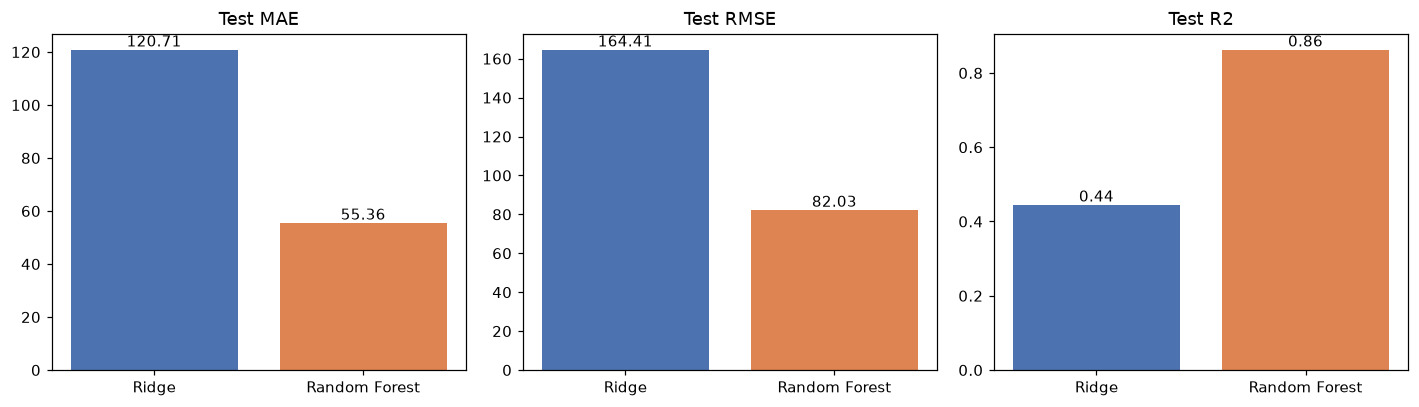

In [13]:
# Metrics comparison (test set)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, metric in zip(ax, ["MAE", "RMSE", "R2"]):
    vals = results[f"Test {metric}"]
    bars = a.bar(vals.index, vals.values, color=["#4C72B0", "#DD8452"])
    a.set_title(f"Test {metric}")
    for b, v in zip(bars, vals.values):
        a.text(b.get_x() + b.get_width()/2, v, f"{v:.2f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

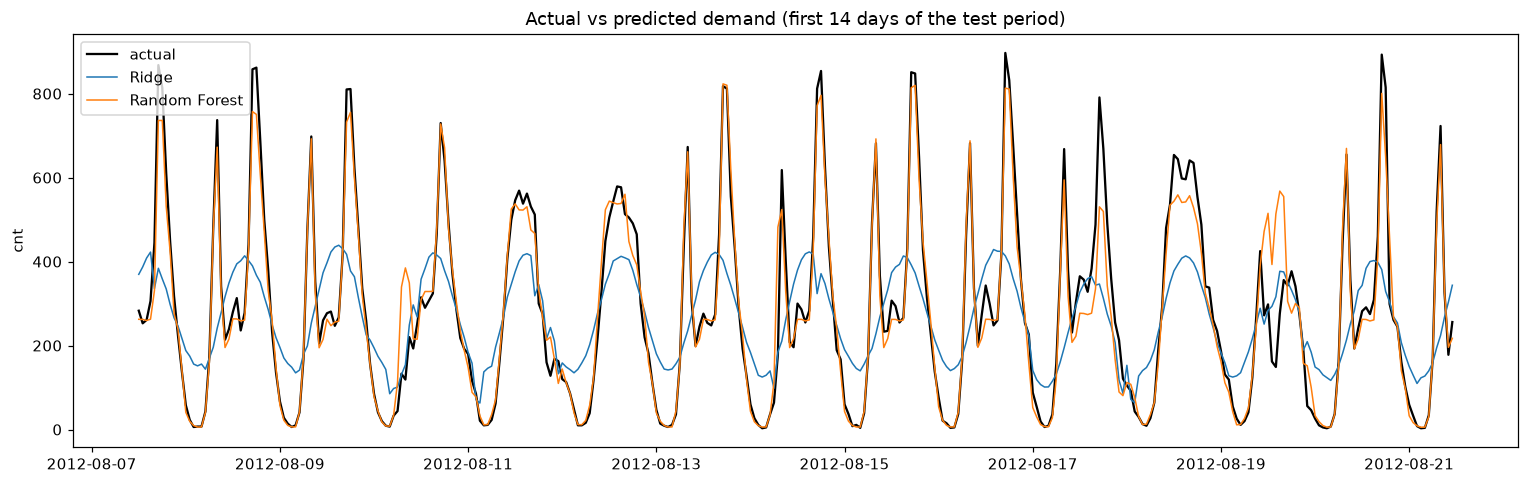

In [14]:
# Actual vs predicted on a 2-week window of the test set
w = slice(0, 24 * 14)
dates = df["dteday"].iloc[n:].reset_index(drop=True) + pd.to_timedelta(hr_test.reset_index(drop=True), unit="h")
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(dates[w], y_test.values[w], "k", lw=1.5, label="actual")
for name, p in preds.items():
    ax.plot(dates[w], p[w], lw=1, label=name)
ax.set_title("Actual vs predicted demand (first 14 days of the test period)")
ax.set_ylabel("cnt"); ax.legend(); plt.tight_layout(); plt.show()

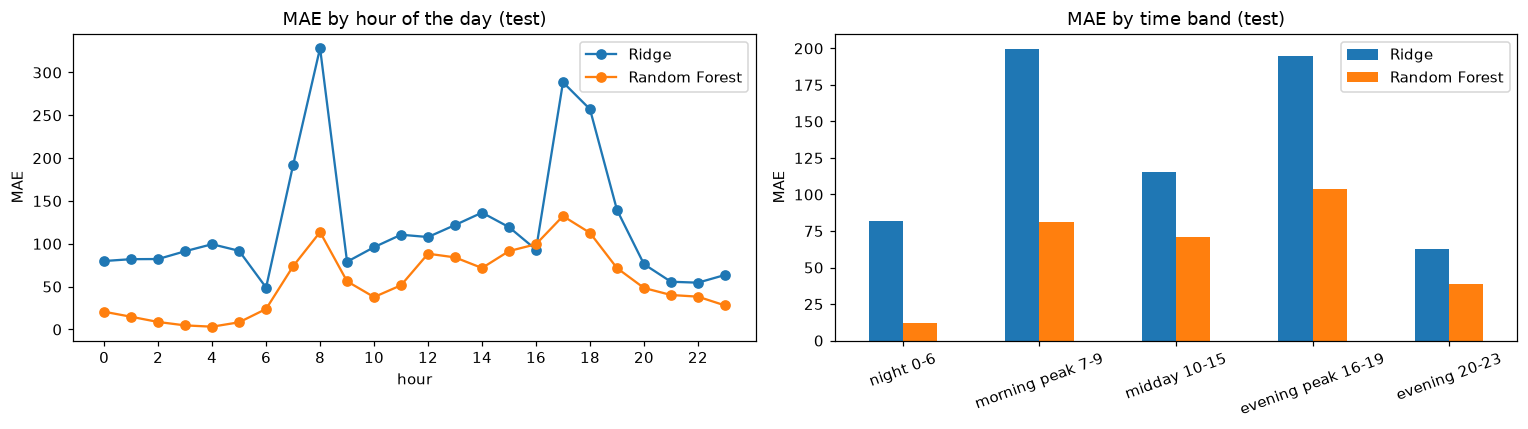

,Ridge,Random Forest
hr,,
night 0-6,82.18,12.10
morning peak 7-9,199.73,81.20
midday 10-15,115.43,70.95
evening peak 16-19,194.61,104.06
evening 20-23,62.52,38.74


In [15]:
# Error analysis by hour of the day
err = pd.DataFrame({"hr": hr_test.values, "y": y_test.values})
for name, p in preds.items():
    err[name] = np.abs(err["y"] - p)
mae_by_hour = err.groupby("hr")[list(preds)].mean()
rmse_by_hour = pd.DataFrame({name: err.groupby("hr").apply(lambda g, nm=name: np.sqrt((g[nm]**2).mean()))
                             for name in preds})

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mae_by_hour.plot(ax=ax[0], marker="o"); ax[0].set_title("MAE by hour of the day (test)")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("MAE"); ax[0].set_xticks(range(0, 24, 2))

bands = pd.cut(err["hr"], bins=[-1, 6, 9, 15, 19, 23],
               labels=["night 0-6", "morning peak 7-9", "midday 10-15", "evening peak 16-19", "evening 20-23"])
mae_by_band = err.groupby(bands)[list(preds)].mean()
mae_by_band.plot.bar(ax=ax[1]); ax[1].set_title("MAE by time band (test)")
ax[1].set_ylabel("MAE"); ax[1].set_xlabel(""); plt.setp(ax[1].get_xticklabels(), rotation=20)
plt.tight_layout(); plt.show()
mae_by_band.round(2)

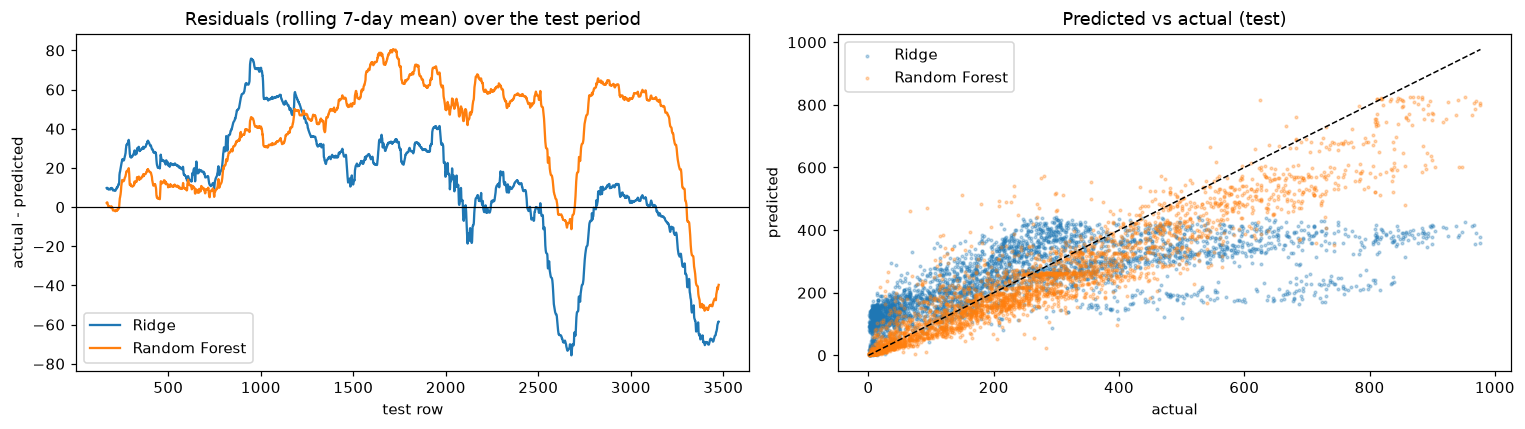

In [16]:
# Residuals over time (drift check) and predicted vs actual scatter
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, p in preds.items():
    res = y_test.values - p
    ax[0].plot(pd.Series(res).rolling(24 * 7).mean().values, label=name)
    ax[1].scatter(y_test.values, p, s=3, alpha=0.3, label=name)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_title("Residuals (rolling 7-day mean) over the test period")
ax[0].set_xlabel("test row"); ax[0].set_ylabel("actual - predicted"); ax[0].legend()
mx = y_test.max(); ax[1].plot([0, mx], [0, mx], "k--", lw=1)
ax[1].set_title("Predicted vs actual (test)"); ax[1].set_xlabel("actual"); ax[1].set_ylabel("predicted"); ax[1].legend()
plt.tight_layout(); plt.show()

## 9. Saving the trained models and pipelines
Each saved file is a **complete pipeline** (preprocessing + trained model), so it can be loaded and applied directly to a feature matrix built with `make_features`.

In [17]:
joblib.dump(best_models["Ridge"],         "saved_models/ridge_pipeline.joblib")
joblib.dump(best_models["Random Forest"], "saved_models/random_forest_pipeline.joblib", compress=3)   # compress: forests can be large

# Data pipeline alone (fitted on the training set only)
data_pipeline = build_preprocessor().fit(X_train)
joblib.dump(data_pipeline, "saved_models/data_preprocessing_pipeline.joblib")

# Results and settings
results.round(4).to_csv("saved_models/test_metrics.csv")
pd.Series({n_: str(gs.best_params_) for n_, gs in searches.items()}).to_csv("saved_models/best_params.csv", header=["best_params"])
joblib.dump({"cat_cols": cat_cols, "num_cols": num_cols, "bin_cols": bin_cols,
             "cyc_cols": cyc_cols, "feature_columns": list(X.columns)}, "saved_models/columns_config.joblib")

for f in sorted(os.listdir("saved_models")):
    print(f"{f:40s} {os.path.getsize('saved_models/' + f) / 1024:9.1f} KB")

best_params.csv                                0.1 KB
columns_config.joblib                          0.3 KB
data_preprocessing_pipeline.joblib             3.3 KB
random_forest_pipeline.joblib              20789.4 KB
ridge_pipeline.joblib                          3.8 KB
test_metrics.csv                               0.2 KB


## 10. Reloading a saved model (check)
To use the models in another script, the function `make_features` must be available (copy it), because it transforms raw rows into the feature matrix.

In [18]:
loaded_rf = joblib.load("saved_models/random_forest_pipeline.joblib")
loaded_ridge = joblib.load("saved_models/ridge_pipeline.joblib")

# Example: raw rows from hour.csv -> features -> prediction
sample_raw = df.iloc[n:n + 5]
sample_X = make_features(sample_raw)
print(pd.DataFrame({
    "actual": sample_raw["cnt"].values,
    "Ridge": loaded_ridge.predict(sample_X).round(1),
    "Random Forest": loaded_rf.predict(sample_X).round(1),
}))

# The reloaded model reproduces the same test score
print("RF test RMSE after reload:", round(evaluate(y_test, loaded_rf.predict(X_test))["RMSE"], 3))

   actual  Ridge  Random Forest
0     283  369.6          262.6
1     253  387.2          262.2
2     261  408.5          259.7
3     306  422.6          262.8
4     445  335.6          331.1
RF test RMSE after reload: 82.034


## Notes for the report
- Observed weather (`temp`, `hum`, `windspeed`, ...) is used as input. In real use only weather **forecasts** are available, so these scores are optimistic.
- Tree-based models cannot extrapolate above the demand levels seen in training. The test period (late 2012) has higher demand than 2011, so look at the residual plot for under-prediction.
- Compare absolute errors at peak hours (8h, 17-18h) with the average demand at those hours before concluding.